<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A03_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [4]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))


Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [5]:
import kagglehub
import os

path = kagglehub.dataset_download("prokshitha/home-value-insights")

csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, file))

for file in csv_files:
    temp_df = pd.read_csv(file)
    if 'House_Price' in temp_df.columns:
        df = temp_df
        print("Завантажено файл:", file)
        break
else:
    raise FileNotFoundError("CSV-файл з ознакою House_Price не знайдено")

Using Colab cache for faster access to the 'home-value-insights' dataset.
Завантажено файл: /kaggle/input/home-value-insights/house_price_regression_dataset.csv


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [6]:
display(df.head())
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [7]:
df.duplicated().sum()

np.int64(0)

### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [8]:
df.isnull().sum()

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [9]:
display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [10]:
df['Neighborhood_Quality'].value_counts().sort_index()

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

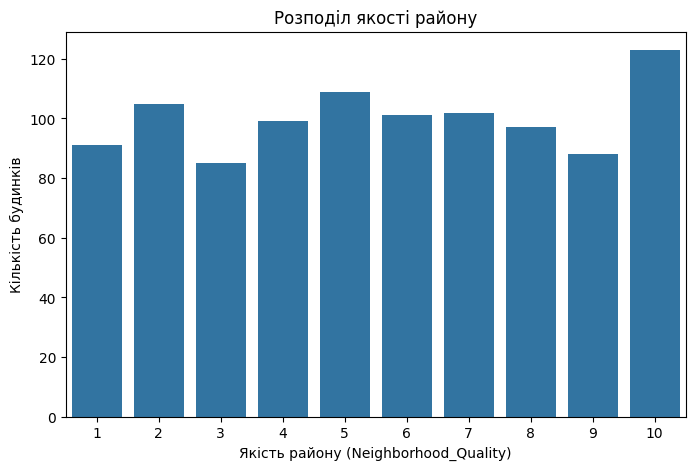

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Neighborhood_Quality',
    order=sorted(df['Neighborhood_Quality'].dropna().unique())
)

plt.title('Розподіл якості району')
plt.xlabel('Якість району (Neighborhood_Quality)')
plt.ylabel('Кількість будинків')
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [12]:
df['Num_Bathrooms'].value_counts().sort_index()

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

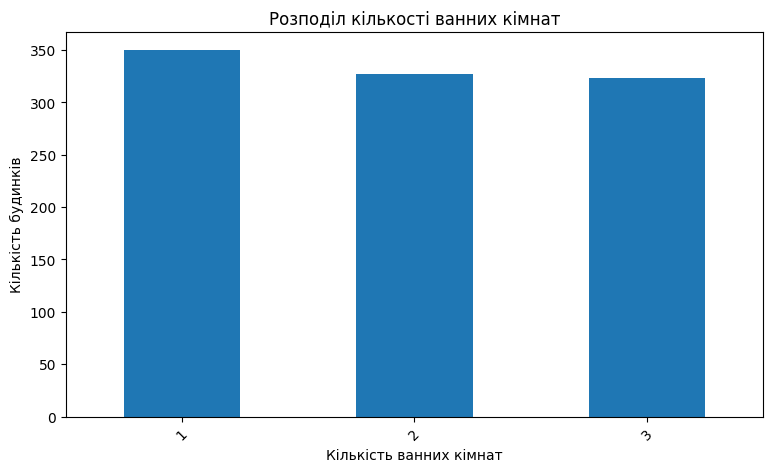

In [13]:
bathroom_counts = df['Num_Bathrooms'].value_counts().sort_index()

plt.figure(figsize=(9, 5))
bathroom_counts.plot(kind='bar')

plt.title('Розподіл кількості ванних кімнат')
plt.xlabel('Кількість ванних кімнат')
plt.ylabel('Кількість будинків')
plt.xticks(rotation=45)
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

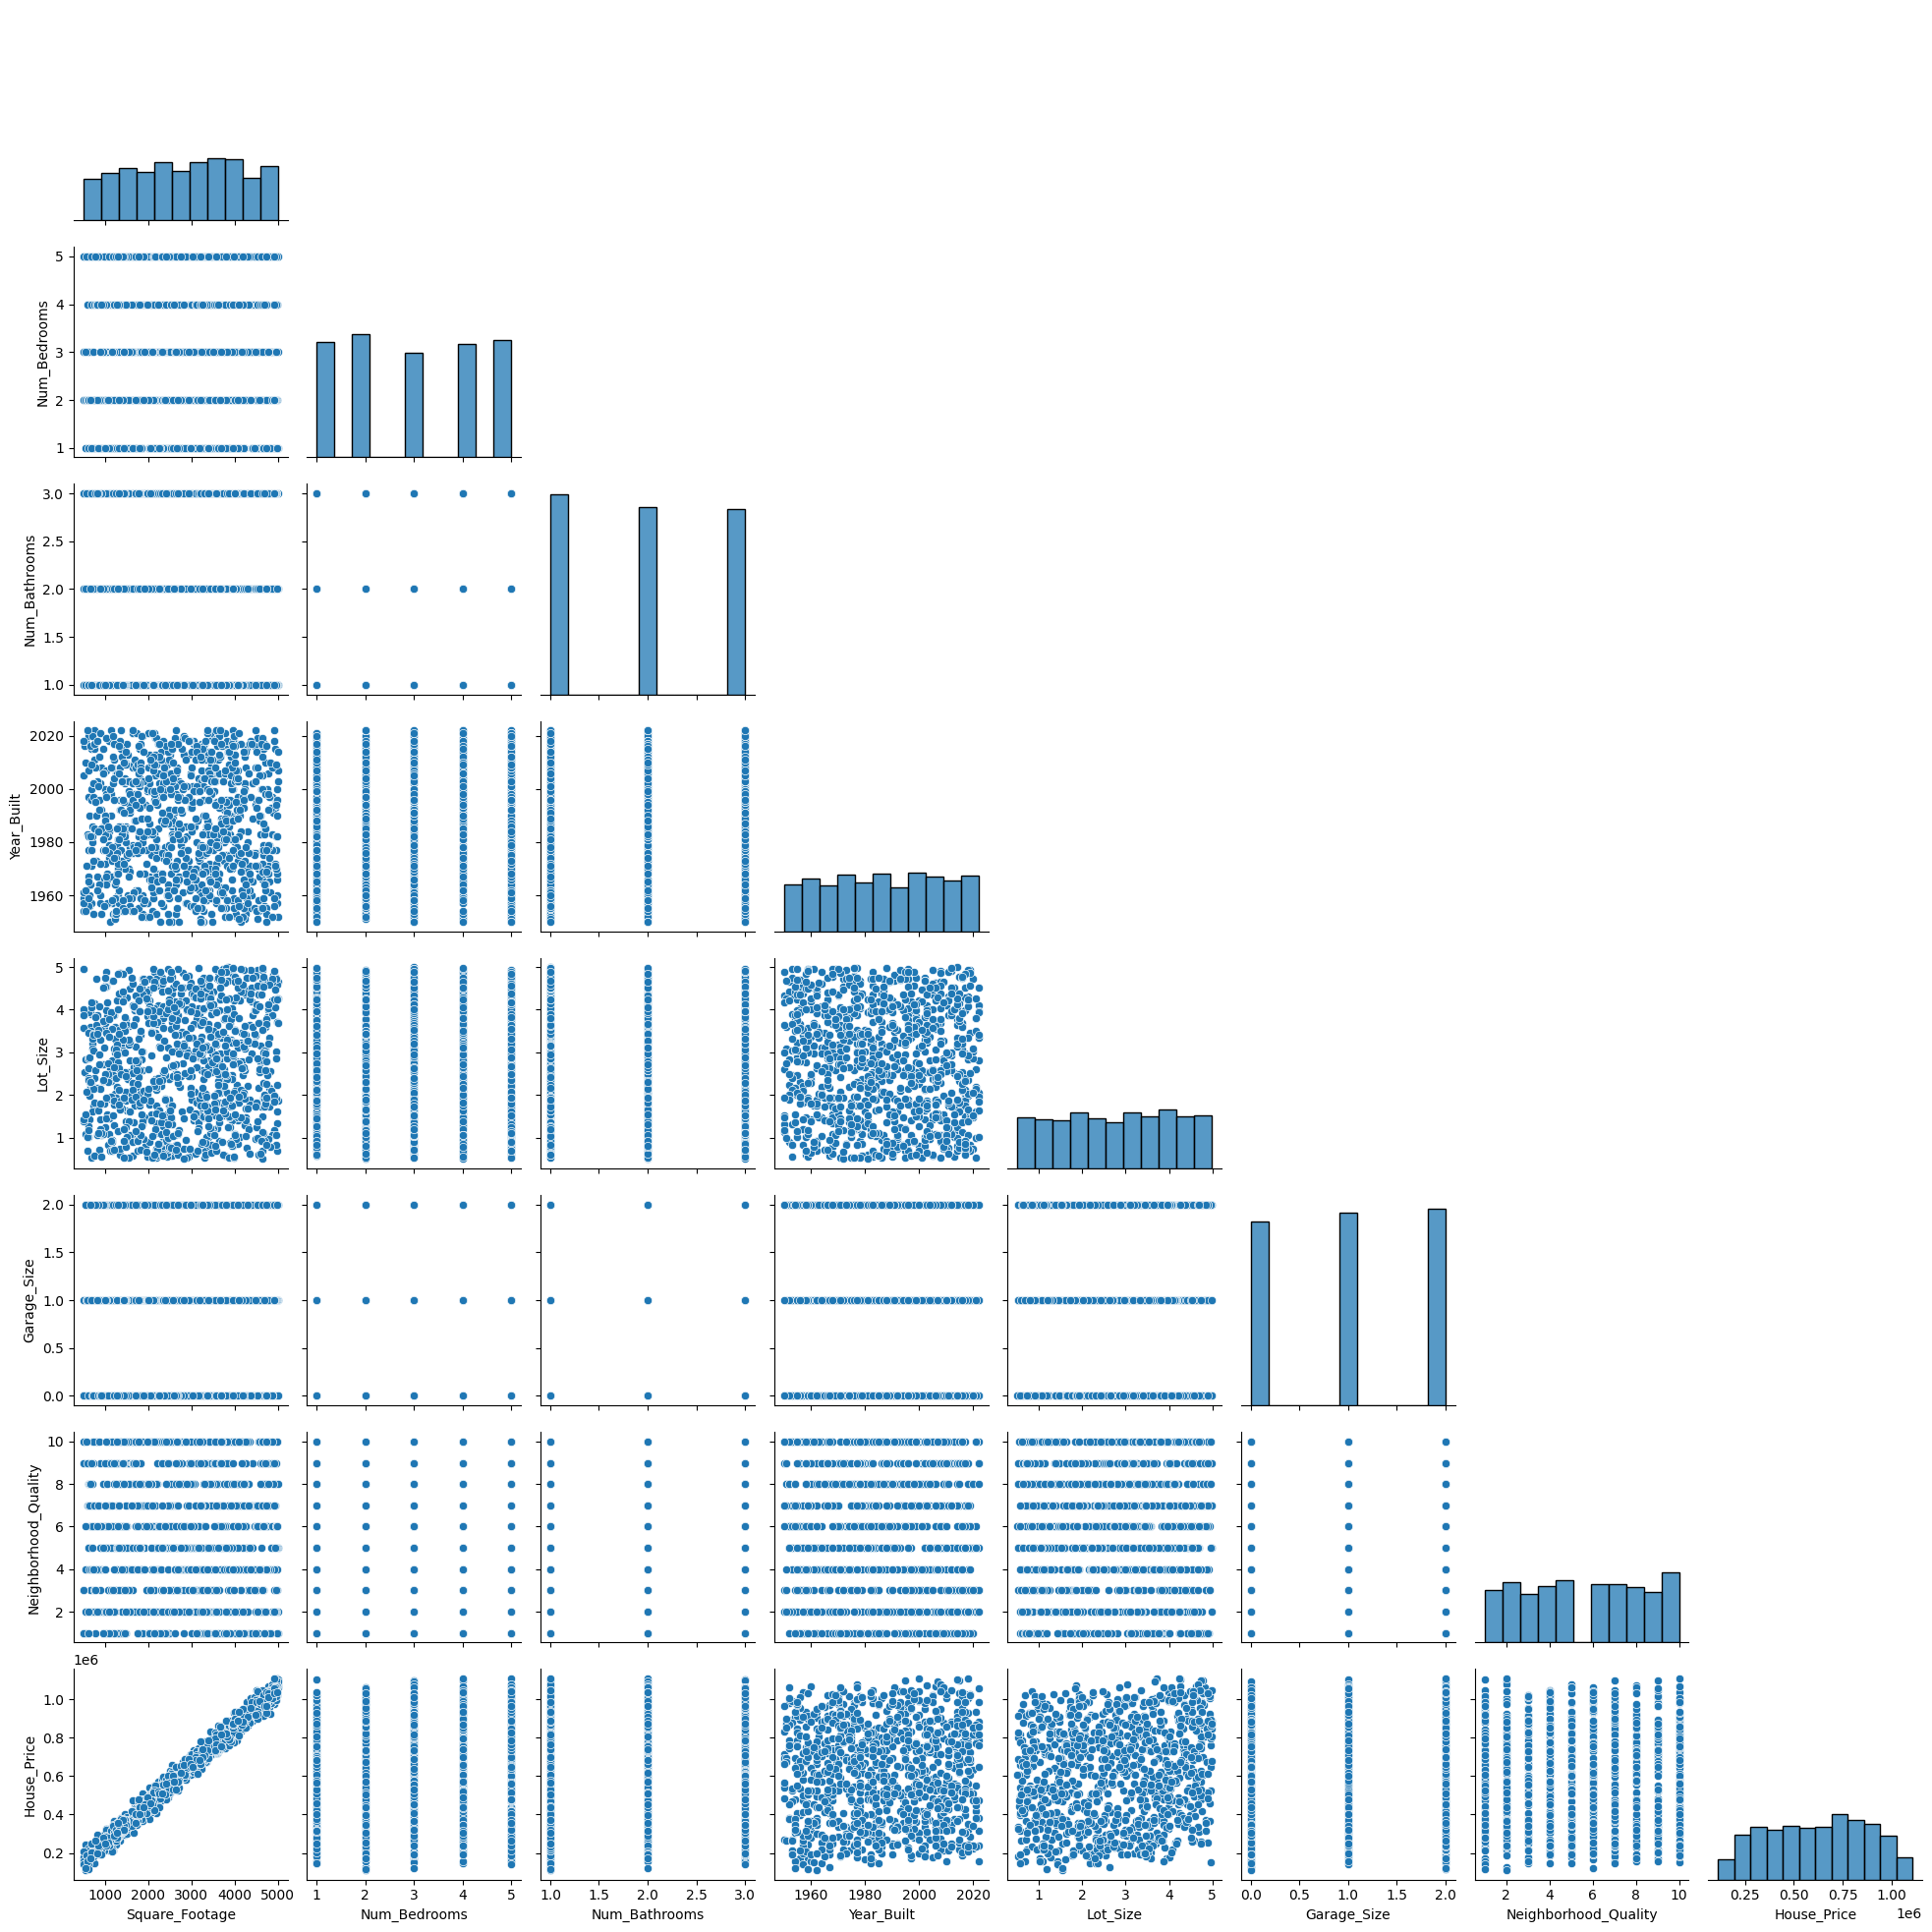

In [14]:
numeric_df = df.select_dtypes(include=np.number)

sns.pairplot(numeric_df, corner=True)
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

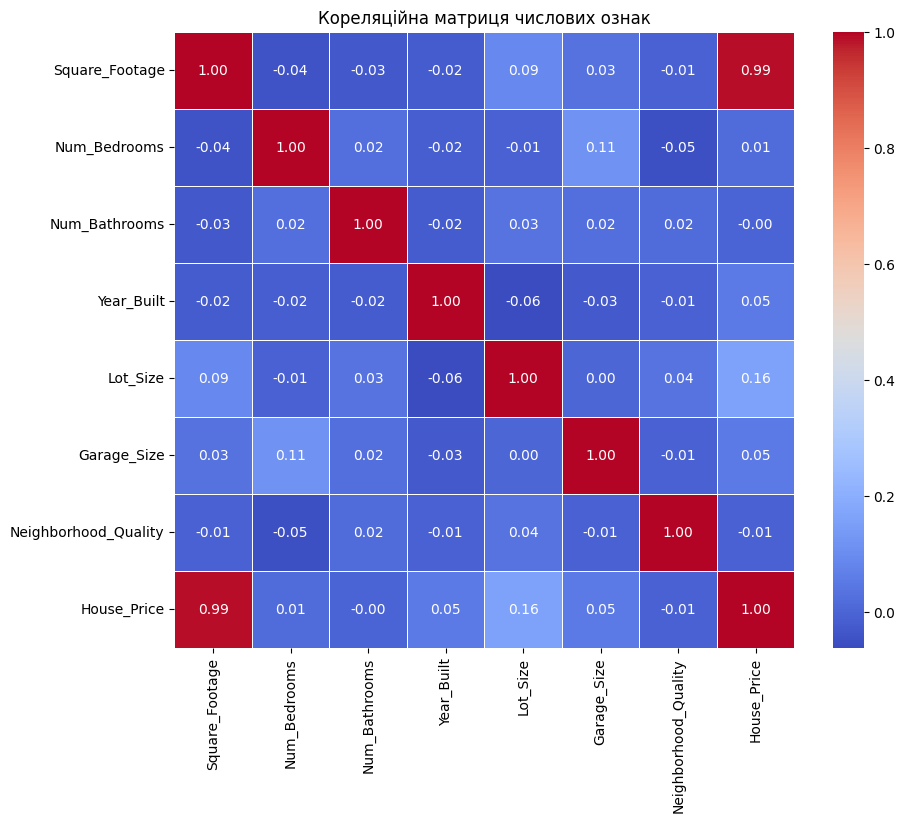

In [15]:
corr_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Кореляційна матриця числових ознак')
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [16]:
correlations = (
    df.select_dtypes(include=np.number)
    .corr()['House_Price']
    .drop('House_Price')
    .sort_values(ascending=False)
)

print(correlations)

Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [17]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [18]:
X = df.drop(columns=['House_Price'])
y = df['House_Price']

# Перетворення категоріальних ознак на числові
X = pd.get_dummies(X, drop_first=True)

# Обробка пропущених значень
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Розмір X: (1000, 7)
Розмір y: (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (800, 7)
Тестова вибірка: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [20]:
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge())
    ]),

    'Lasso': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(max_iter=10000))
    ]),

    'Random Forest': RandomForestRegressor(
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

print("Створено моделей:", len(models))

Створено моделей: 5


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [21]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,R2,MAE,MSE
0,Linear Regression,0.9984,8174.5836,1.014348e+08
1,Ridge,0.9984,8241.5869,1.024810e+08
2,Lasso,0.9984,8174.7484,1.014366e+08
3,Random Forest,0.9939,16114.2896,3.941317e+08
4,Gradient Boosting,0.9965,12305.2176,2.249656e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

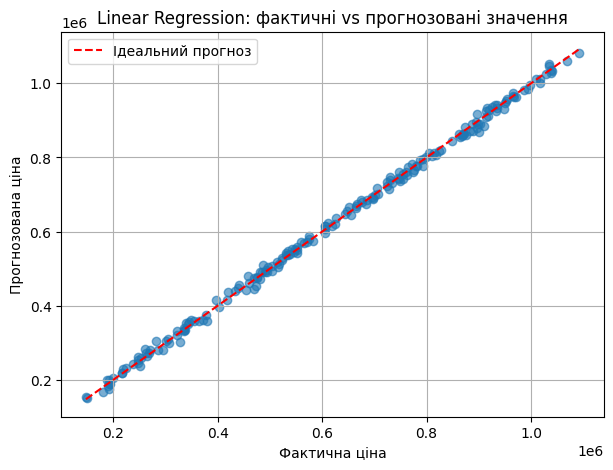

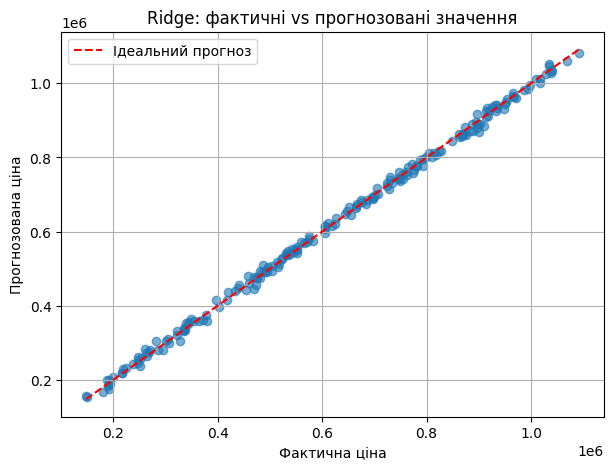

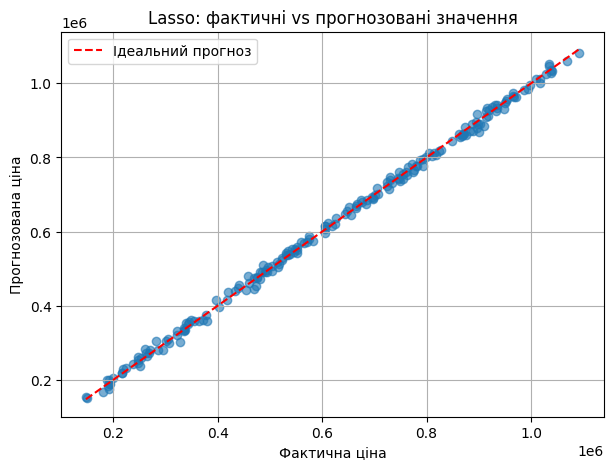

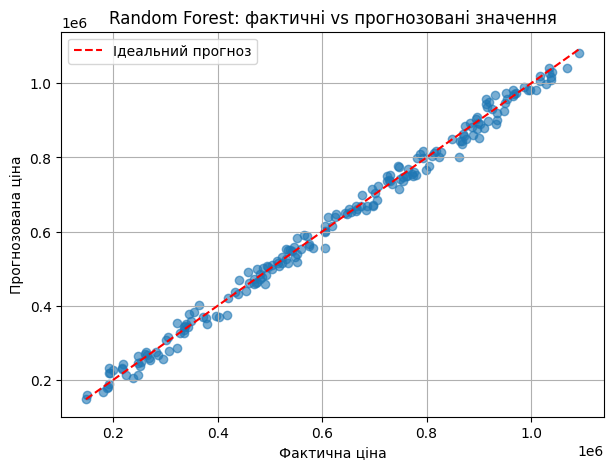

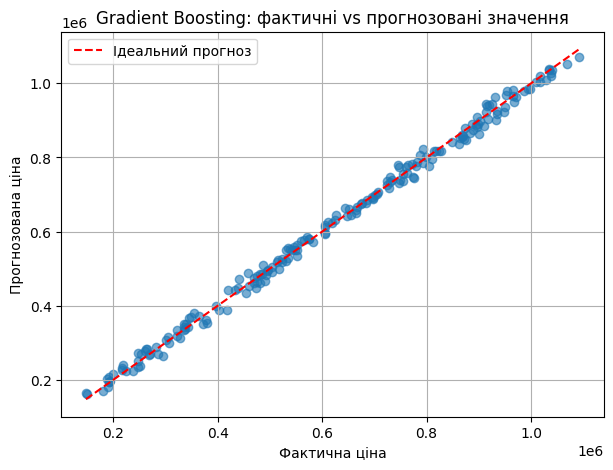

In [22]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred, alpha=0.6)

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        'r--',
        label='Ідеальний прогноз'
    )

    plt.xlabel('Фактична ціна')
    plt.ylabel('Прогнозована ціна')
    plt.title(f'{name}: фактичні vs прогнозовані значення')
    plt.legend()
    plt.grid(True)
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [23]:
param_grid = {
    'n_estimators': [100, 200],
    'max_features': ['sqrt', 1.0],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкращий середній R² на крос-валідації:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри:
{'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}

Найкращий середній R² на крос-валідації:
0.992


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [24]:
best_rf = RandomForestRegressor(
    **grid_search.best_params_,
    random_state=42
)

best_rf.fit(X_train, y_train)

y_pred_optimized = best_rf.predict(X_test)

optimized_results = {
    'Model': 'Optimized Random Forest',
    'R2': r2_score(y_test, y_pred_optimized),
    'MAE': mean_absolute_error(y_test, y_pred_optimized),
    'MSE': mean_squared_error(y_test, y_pred_optimized)
}

display(pd.DataFrame([optimized_results]).round(4))

,Model,R2,MAE,MSE
0,Optimized Random Forest,0.994,16035.1681,3.872291e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [25]:
baseline_rf = results_df[
    results_df['Model'] == 'Random Forest'
].iloc[0]

comparison_df = pd.DataFrame([
    {
        'Model': 'Random Forest до оптимізації',
        'R2': baseline_rf['R2'],
        'MAE': baseline_rf['MAE'],
        'MSE': baseline_rf['MSE']
    },
    {
        'Model': 'Random Forest після оптимізації',
        'R2': optimized_results['R2'],
        'MAE': optimized_results['MAE'],
        'MSE': optimized_results['MSE']
    }
])

display(comparison_df.round(4))

,Model,R2,MAE,MSE
0,Random Forest до оптимізації,0.9939,16114.2896,3.941317e+08
1,Random Forest після оптимізації,0.9940,16035.1681,3.872291e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Мій висновок:**
Оптимізація моделі Random Forest за допомогою GridSearchCV дозволила підібрати найкращі гіперпараметри шляхом крос-валідації. Для порівняння ефективності базового та оновленого алгоритмів використовувалися три ключові метрики: R², MAE та MSE.
Доцільність переходу на оптимізовану модель визначається позитивною динамікою цих показників: зростанням коефіцієнта детермінації (R²) на тлі зниження помилок (MAE та MSE). Якщо ж метрики залишилися незмінними або погіршилися, ефективніше залишити базову модель, оскільки вона потребує значно менше часу на навчання.


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [26]:
linear_pred = predictions['Linear Regression']

forecast_df = pd.DataFrame({
    'Фактична ціна': y_test.to_numpy(),
    'Прогнозована ціна': linear_pred,
})

forecast_df['Похибка (%)'] = np.where(
    forecast_df['Фактична ціна'] != 0,
    np.abs(
        forecast_df['Фактична ціна'] -
        forecast_df['Прогнозована ціна']
    ) / np.abs(forecast_df['Фактична ціна']) * 100,
    np.nan
)

display(
    forecast_df.sample(
        n=min(10, len(forecast_df)),
        random_state=42
    ).round(2)
)

,Фактична ціна,Прогнозована ціна,Похибка (%)
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:** У межах лабораторної роботи було розроблено та досліджено п’ять регресійних моделей для прогнозування вартості нерухомості. Найвищу точність продемонстрували моделі Linear Regression та Lasso, які досягли коефіцієнта детермінації R² = 0,998426 при середній абсолютній помилці MAE на рівні 8175. Оптимізація гіперпараметрів моделі Random Forest також дала позитивний ефект: показник R² зріс з 0,993886 до 0,993993 на тлі зниження помилок MAE та MSE. Проте для цільового датасету найефективнішим інструментом прогнозування виявилася лінійна регресія.
На підсумкові результати вартості житла суттєво впливають такі предиктори, як загальна площа, кількість кімнат і санвузлів, інфраструктура й престижність району, а також його географічне розташування. Виконана робота дозволила практично закріпити навички з препроцесингу даних, конструювання моделей регресії, валідації їхньої якості та оптимізації параметрів для максимізації точності передбачень.
